# Baselines

The four simple baselines from the proposal, evaluated the same way the transformer will be:

1. **Stay still**: the player stays where they are for the next 10 s.
2. **Constant velocity**: the player keeps moving at their current velocity.
3. **Nearest neighbours (kNN)**: copy what happened next in the 6 most similar training situations.
4. **Per-player GRU**: a GRU that sees only one player's own last 10 s and outputs 6 paths with probabilities.

Metrics are on the **test** matches (never seen in training), at 3, 5 and 10 s:

- **minADE@6 / minFDE@6**: average / endpoint distance (game units) of the closest of the 6 paths.
- **ADE / FDE (top-1)**: the same for the single most likely path.
- **Miss rate**: how often the closest endpoint is more than 200 units off.
- **Brier-minFDE@6**: minFDE@6 plus 200 × (1 − p)², where p is the probability the model gave its closest path.
  It rewards knowing *which* of the 6 paths will happen, not just covering it.
- **Callout accuracy**: whether the endpoint lands in the right Mirage callout (`TopofMid`, `Connector`, ...),
  for the most likely path (top-1) and for any of the 6 paths (@6).
- **Off-map**: share of predicted points outside the area players walked on in training.

Stay still and constant velocity output one path, so for them the @6 and top-1 numbers are the same.

One sample = one player who is alive at prediction time *t*, predicted every 0.5 s, with the same
targets and death/round-end masking as `dataset.py`. A horizon only counts samples where the player is
still alive and the round still running at that horizon. Results are reported for all players and for
**moving** players (speed of at least 100 u/s at time *t*).

In [1]:
import hashlib
import json
import time
from contextlib import contextmanager
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.ndimage import binary_dilation
from sklearn.neighbors import NearestNeighbors

from features import G, HORIZON_SECONDS, P, S, SLOTS_PER_SIDE, STEP_SECONDS

PROCESSED = Path("processed")
manifest = json.loads((PROCESSED / "manifest.json").read_text())
POS_MEAN = np.array(manifest["pos_mean"], np.float32)
POS_STD = np.float32(manifest["pos_std"])

H = int(round(HORIZON_SECONDS / STEP_SECONDS))  # 20 future steps
L = 20  # history steps (10 s) given to the kNN and GRU baselines
K = 6  # predicted paths per player
HORIZONS = {3: 6, 5: 10, 10: 20}  # seconds -> steps
MISS_UNITS = 200
BRIER_SCALE = 200  # units per unit of (1 - p)^2: being sure of the wrong path costs as much as a miss
MOVING_SPEED = 100  # u/s at prediction time

rng = np.random.default_rng(0)
torch.manual_seed(0)
pd.set_option("display.precision", 1)

timings = {}  # model -> {"fit / train s": ..., "predict test s": ..., ...}


@contextmanager
def timed(model, what):
    start = time.perf_counter()
    yield
    timings.setdefault(model, {})[what] = time.perf_counter() - start


LOG_PATH = Path("logs/baselines.log")  # follow a run with: Get-Content logs/baselines.log -Wait
LOG_PATH.parent.mkdir(exist_ok=True)


def log(message):
    """Print and append to LOG_PATH right away, so progress is visible while the notebook runs."""
    line = f"{time.strftime('%Y-%m-%d %H:%M:%S')}  {message}"
    print(line)
    with LOG_PATH.open("a", encoding="utf-8") as f:
        f.write(line + "\n")


log(f"=== baselines run started: CPU threads {torch.get_num_threads()}, torch {torch.__version__}")

2026-10-28 10:37:45  === baselines run started: CPU threads 8, torch 2.4.1+cpu


## Per-player samples

Built straight from `processed/*.npz` with numpy (much faster than going through `MirageWindows`
one window at a time). `hist` is the player's last `L` positions (oldest first, padded with the first
position of the round), `fut` the next `H` positions, and `mask` marks the future steps where the
player is alive and the round is still running.

In [2]:
PLACE_IDS = {name: i for i, name in enumerate(manifest["place_vocab"])}


def load_split(split):
    parts = []
    entries = [e for e in manifest["demos"] if e["split"] == split]
    for demo_idx, entry in enumerate(entries):
        with np.load(PROCESSED / entry["file"]) as z:
            p, glob, side, slot_valid = z["player"], z["globals"], z["side"], z["round_slot_valid"]
            # Per-demo callout ids -> global place_vocab ids (0 = no callout).
            remap = np.array([PLACE_IDS.get(s, 0) if s else 0 for s in z["place_strings"].tolist()])
            place = remap[z["player_cat"][..., 1]]  # [steps, 10]
            for r, (off, n) in enumerate(zip(z["round_offset"].tolist(), z["round_n_steps"].tolist())):
                xy = p[off:off + n, :, [P["X"], P["Y"]]]
                alive = (p[off:off + n, :, P["is_alive"]] > 0) & slot_valid[r]
                steps = np.arange(n)
                fut = steps[:, None] + np.arange(1, H + 1)
                fut_xy = xy[np.minimum(fut, n - 1)]  # [n, H, 10, 2]
                fut_mask = alive[np.minimum(fut, n - 1)] & (fut < n)[..., None]  # [n, H, 10]
                hist_xy = xy[np.maximum(steps[:, None] - np.arange(L - 1, -1, -1), 0)]  # [n, L, 10, 2]
                round_place = place[off:off + n]
                fut_place = round_place[np.minimum(fut, n - 1)]  # [n, H, 10]
                t, s = np.nonzero(alive[: n - 1])  # need at least one future step, as in dataset.py
                parts.append({
                    "anchor": xy[t, s],
                    "vel": p[off + t, s][:, [P["vel_x"], P["vel_y"]]],
                    "hist": hist_xy[t, :, s],
                    "fut": fut_xy[t, :, s],
                    "mask": fut_mask[t, :, s],
                    "place": round_place[t, s],
                    "fut_place": fut_place[t, :, s],
                    "side": (s >= SLOTS_PER_SIDE).astype(np.float32),  # 0 = T, 1 = CT
                    "time": glob[off + t, G["time_since_freeze_end"]],
                    "planted": glob[off + t, G["bomb_planted"]],
                    # economy and score: the player's own and their team's (enemy equipment is hidden from a team)
                    "score_own": side[off + t, s // SLOTS_PER_SIDE, S["score"]],
                    "score_enemy": side[off + t, 1 - s // SLOTS_PER_SIDE, S["score"]],
                    "equip": p[off + t, s, P["equip_value"]],
                    "team_equip": side[off + t, s // SLOTS_PER_SIDE, S["equip_value"]],
                    "meta": np.stack([np.full_like(t, demo_idx), np.full_like(t, r), t, s], 1),
                })
    d = {k: np.concatenate([part[k] for part in parts]) for k in parts[0]}
    for k in d:
        if k not in ("mask", "meta", "place", "fut_place"):
            d[k] = d[k].astype(np.float32)
    d["fut"][~d["mask"]] = 0  # positions after death are meaningless
    d["moving"] = np.linalg.norm(d["vel"], axis=1) >= MOVING_SPEED
    return d


with timed("data", "load s"):
    data = {split: load_split(split) for split in ("train", "val", "test")}
log(f"data loaded in {timings['data']['load s']:.1f}s: " + ", ".join(f"{s} {len(d['anchor'])} samples" for s, d in data.items()))
pd.DataFrame({
    split: {
        "demos": sum(e["split"] == split for e in manifest["demos"]),
        "player samples": len(d["anchor"]),
        "moving": int(d["moving"].sum()),
        **{f"alive at {sec}s": int(d["mask"][:, h - 1].sum()) for sec, h in HORIZONS.items()},
    }
    for split, d in data.items()
})

2026-10-28 10:37:45  data loaded in 0.4s: train 257856 samples, val 22855 samples, test 25794 samples


,train,val,test
demos,9,1,1
player samples,257856,22855,25794
moving,145253,13021,13990
alive at 3s,247164,21843,24778
alive at 5s,239524,21123,24058
alive at 10s,220436,19323,22258


Sanity check: the targets match `MirageWindows` from `dataset.py` on random test windows.

In [3]:
from dataset import MirageWindows

test = data["test"]
assert np.isfinite(test["anchor"]).all() and np.isfinite(test["hist"]).all()
ds = MirageWindows(str(PROCESSED), split="test")
lookup = {tuple(m): i for i, m in enumerate(test["meta"].tolist())}
for i in rng.choice(len(ds), 300, replace=False):
    item = ds[i]
    demo_idx, r, t, pov = (int(v) for v in ds.index[i])
    for j in range(SLOTS_PER_SIDE):
        key = (demo_idx, r, t, pov * SLOTS_PER_SIDE + j)
        if not item["anchor_alive"][j]:
            assert key not in lookup
            continue
        k = lookup[key]
        assert np.array_equal(item["target_mask"][:, j].numpy(), test["mask"][k])
        assert np.allclose(item["target_xy"][:, j].numpy(), test["fut"][k])
        assert np.allclose(item["anchor_xy"][j].numpy(), test["anchor"][k])
log("sanity check passed: targets match dataset.py")
del ds

2026-10-28 10:37:45  sanity check passed: targets match dataset.py


## Metrics

Every model returns `pred` with shape `[N, k, H, 2]` (absolute positions, game units) and `prob` with
shape `[N, k]`.

For the off-map rate, "walkable" is every 64-unit cell that a living player stood in during
training, grown by one cell. With little training data this is a rough proxy, so the ground-truth row
gives the floor: how often *real* test positions land outside it.

Callouts for real positions come from the game (`last_place_name`, parsed by awpy). Predicted points
have none, so each gets the callout of the nearest training position. That lookup is 2D, so stacked
areas (e.g. Underpass below Middle) can be mixed up; the ground-truth row runs the same lookup on the
true endpoints, which gives the ceiling any model can reach.

In [4]:
CELL = 64
train_cells = np.floor(data["train"]["hist"].reshape(-1, 2) / CELL).astype(int)
grid_lo = train_cells.min(0) - 2
walkable = np.zeros(train_cells.max(0) - grid_lo + 3, bool)
walkable[tuple((train_cells - grid_lo).T)] = True
walkable = binary_dilation(walkable, iterations=1)


def off_map_rate(points):
    c = np.floor(points.reshape(-1, 2) / CELL).astype(int) - grid_lo
    inside = ((c >= 0) & (c < walkable.shape)).all(1)
    off = ~inside
    off[inside] = ~walkable[c[inside, 0], c[inside, 1]]
    return off.mean()


known_place = data["train"]["place"] > 0
place_index = NearestNeighbors(n_neighbors=1).fit(data["train"]["anchor"][known_place])
place_labels = data["train"]["place"][known_place]


def callout(points):
    """Callout id of the nearest training position for each point ([..., 2] -> [...])."""
    nearest = place_index.kneighbors(points.reshape(-1, 2), return_distance=False)[:, 0]
    return place_labels[nearest].reshape(points.shape[:-1])


def evaluate(pred, prob, d):
    rows = []
    for subset, sel in (("all", np.ones(len(d["anchor"]), bool)), ("moving", d["moving"])):
        for sec, h in HORIZONS.items():
            ok = sel & d["mask"][:, h - 1]
            p = pred[ok][:, :, :h]
            err = np.linalg.norm(p - d["fut"][ok][:, None, :h], axis=-1)  # [n, k, h]
            ade, fde = err.mean(-1), err[..., -1]
            pr = prob[ok]
            top = pr.argmax(1)
            n = np.arange(len(top))
            closest = fde.argmin(1)
            end_place = callout(p[:, :, -1])  # [n, k]
            true_place = d["fut_place"][ok, h - 1]
            labelled = true_place > 0
            rows.append({
                "subset": subset, "horizon": f"{sec}s",
                "minADE@6": ade.min(1).mean(), "minFDE@6": fde.min(1).mean(),
                "ADE top-1": ade[n, top].mean(), "FDE top-1": fde[n, top].mean(),
                "miss rate %": 100 * (fde.min(1) > MISS_UNITS).mean(),
                "Brier-minFDE@6": (fde.min(1) + BRIER_SCALE * (1 - pr[n, closest]) ** 2).mean(),
                "callout top-1 %": 100 * (end_place[n, top] == true_place)[labelled].mean(),
                "callout @6 %": 100 * (end_place == true_place[:, None]).any(1)[labelled].mean(),
                "off-map %": 100 * off_map_rate(p),
                "samples": int(ok.sum()),
            })
    return pd.DataFrame(rows)


results = {}
truth = test["fut"][:, None]
gt = evaluate(truth, np.ones((len(truth), 1)), test)
results["ground truth (floor / ceiling)"] = gt.assign(
    **{c: np.nan for c in gt.columns if c not in ("subset", "horizon", "off-map %", "callout top-1 %", "samples")}
)

## 1. Stay still

In [5]:
def stay_still(d):
    return np.repeat(d["anchor"][:, None, None], H, 2), np.ones((len(d["anchor"]), 1))


with timed("stay still", "predict test s"):
    stay_pred = stay_still(test)
results["stay still"] = evaluate(*stay_pred, test)
log("stay still: done")
results["stay still"]

2026-10-28 10:37:46  stay still: done


,subset,horizon,minADE@6,minFDE@6,ADE top-1,FDE top-1,miss rate %,Brier-minFDE@6,callout top-1 %,callout @6 %,off-map %,samples
0,all,3s,149.0,237.9,149.0,237.9,48.1,237.9,71.5,71.5,0.0,24778
1,all,5s,213.8,350.4,213.8,350.4,57.6,350.4,60.8,60.8,0.0,24058
2,all,10s,341.2,551.4,341.2,551.4,69.3,551.4,47.5,47.5,0.0,22258
3,moving,3s,218.4,341.3,218.4,341.3,70.0,341.3,63.1,63.1,0.0,13458
4,moving,5s,305.6,485.6,305.6,485.6,76.9,485.6,49.9,49.9,0.0,13081
5,moving,10s,464.9,711.8,464.9,711.8,83.7,711.8,37.1,37.1,0.0,12115


## 2. Constant velocity

Extrapolates the game's velocity at time *t* (units per second).

In [6]:
DT = STEP_SECONDS * np.arange(1, H + 1, dtype=np.float32)


def constant_velocity(d):
    pred = d["anchor"][:, None, None] + d["vel"][:, None, None] * DT[None, None, :, None]
    return pred, np.ones((len(d["anchor"]), 1))


with timed("constant velocity", "predict test s"):
    cv_pred = constant_velocity(test)
results["constant velocity"] = evaluate(*cv_pred, test)
log("constant velocity: done")
results["constant velocity"]

2026-10-28 10:37:47  constant velocity: done


,subset,horizon,minADE@6,minFDE@6,ADE top-1,FDE top-1,miss rate %,Brier-minFDE@6,callout top-1 %,callout @6 %,off-map %,samples
0,all,3s,130.7,249.7,130.7,249.7,52.6,249.7,65.5,65.5,6.5,24778
1,all,5s,231.0,463.9,231.0,463.9,72.8,463.9,49.7,49.7,12.6,24058
2,all,10s,501.7,1031.9,501.7,1031.9,85.0,1031.9,32.2,32.2,22.1,22258
3,moving,3s,173.5,338.3,173.5,338.3,71.9,338.3,56.5,56.5,10.7,13458
4,moving,5s,314.6,645.4,314.6,645.4,92.0,645.4,36.4,36.4,20.0,13081
5,moving,10s,705.9,1479.4,705.9,1479.4,99.1,1479.4,18.7,18.7,34.2,12115


## 3. Nearest neighbours (6 most similar past situations)

Each situation is described by the player's position, velocity, where they were 1 s and 2 s ago,
time since freeze end, bomb planted, side (weighted heavily so neighbours are always on the same
side), the score of both teams, and the player's own and their team's equipment value (the enemy's is
hidden from a team, so it is left out). Positions and velocities are scaled so 250 units ≈ 250 u/s ≈ 30 s of round time ≈ 4 rounds of
score ≈ $2,500 of the player's equipment ≈ $10,000 of team equipment. Each of the
6 neighbours' next 10 s of movement (as an offset, held at the last position if they died) is applied
to the query player's position; neighbours are weighted by inverse distance.

In [7]:
def knn_features(d):
    rel = d["hist"] - d["anchor"][:, None]  # past positions relative to now; index L-1 is now
    return np.column_stack([
        d["anchor"] / 250,
        d["vel"] / 250,
        rel[:, L - 3] / 250,  # 1 s ago
        rel[:, L - 5] / 250,  # 2 s ago
        d["time"] / 30,
        2 * d["planted"],
        10 * d["side"],
        d["score_own"] / 4,  # 4 rounds of score = 1 unit
        d["score_enemy"] / 4,
        d["equip"] / 2500,  # $2,500 of the player's equipment = 1 unit
        d["team_equip"] / 10000,  # $10,000 of team equipment = 1 unit
    ])


def future_offsets(d):
    """Next H positions relative to the anchor, holding the last valid one after death/round end."""
    last = d["mask"].sum(1) - 1  # the mask is a prefix: once dead, always dead
    idx = np.clip(np.minimum(np.arange(H), last[:, None]), 0, None)
    off = np.take_along_axis(d["fut"], idx[..., None], 1) - d["anchor"][:, None]
    off[last < 0] = 0
    return off


train = data["train"]
with timed("kNN (k=6)", "fit / train s"):
    knn_index = NearestNeighbors(n_neighbors=K).fit(knn_features(train))
    train_offsets = future_offsets(train)


def knn(d):
    dist, idx = knn_index.kneighbors(knn_features(d))
    weight = 1 / (dist + 1e-3)
    return d["anchor"][:, None, None] + train_offsets[idx], weight / weight.sum(1, keepdims=True)


with timed("kNN (k=6)", "predict test s"):
    knn_pred = knn(test)
log(f"kNN: fit {timings['kNN (k=6)']['fit / train s']:.1f}s, test queries {timings['kNN (k=6)']['predict test s']:.1f}s")
results["kNN (k=6)"] = evaluate(*knn_pred, test)
results["kNN (k=6)"]

2026-10-28 10:37:49  kNN: fit 0.9s, test queries 1.5s


,subset,horizon,minADE@6,minFDE@6,ADE top-1,FDE top-1,miss rate %,Brier-minFDE@6,callout top-1 %,callout @6 %,off-map %,samples
0,all,3s,54.5,81.6,107.6,185.4,10.2,220.3,74.3,94.7,0.2,24778
1,all,5s,86.6,136.4,167.5,301.9,22.2,275.2,62.8,89.7,0.2,24058
2,all,10s,163.8,261.2,304.2,544.6,44.1,400.6,45.4,78.3,0.3,22258
3,moving,3s,61.2,90.0,117.8,204.0,11.5,228.8,72.5,94.6,0.2,13458
4,moving,5s,95.5,146.4,184.6,335.9,23.8,285.2,59.9,89.5,0.3,13081
5,moving,10s,175.3,267.5,337.4,603.5,45.2,407.0,41.4,78.6,0.3,12115


## 4. Per-player GRU

Sees only one player: their last 10 s of positions and per-step movement, plus side, round time and
whether the bomb is planted (no teammates, enemies or utility). It outputs 6 paths as cumulative
per-step offsets plus a probability for each path. Trained winner-takes-all: the regression loss only
updates the closest path, and the probabilities learn to pick it. Early stopping on validation minADE@6. The trained weights are saved to `checkpoints/`, so re-running
the notebook (e.g. after changing a metric) reuses them as long as the training data is
identical (checked with a hash); set `RETRAIN_GRU = True` to train again.

In [8]:
OFFSET_SCALE = 100.0  # one output unit = 100 game units of movement per 0.5 s step
device = torch.device("cpu")


def gru_inputs(d):
    pos = (d["hist"] - POS_MEAN) / POS_STD
    step = np.diff(d["hist"], axis=1, prepend=d["hist"][:, :1]) / 125.0  # 125 units = running for 0.5 s
    static = np.column_stack([d["side"], d["time"] / 115.0, d["planted"]])
    return torch.from_numpy(np.concatenate([pos, step, np.repeat(static[:, None], L, 1)], -1).astype(np.float32))


class PlayerGRU(nn.Module):
    def __init__(self, n_in, hidden=128):
        super().__init__()
        self.gru = nn.GRU(n_in, hidden, num_layers=2, batch_first=True, dropout=0.1)
        self.head = nn.Sequential(nn.Linear(hidden, 256), nn.ReLU(), nn.Linear(256, K * (2 * H + 1)))

    def forward(self, x):
        _, h = self.gru(x)
        out = self.head(h[-1]).view(-1, K, 2 * H + 1)
        offsets = out[..., :-1].reshape(-1, K, H, 2).cumsum(2) * OFFSET_SCALE
        return offsets, out[..., -1]


def wta_loss(offsets, logits, target, mask):
    err = ((offsets - target[:, None]) ** 2).sum(-1).add(1e-6).sqrt()  # [B, K, H]
    m = mask[:, None].float()
    ade = (err * m).sum(-1) / m.sum(-1).clamp(min=1)
    best = ade.argmin(1)
    return ade.gather(1, best[:, None]).mean() / OFFSET_SCALE + F.cross_entropy(logits, best)


def tensors(d):
    keep = d["mask"][:, 0]  # samples with no valid future step carry no signal
    return (
        gru_inputs({k: v[keep] for k, v in d.items()}),
        torch.from_numpy(d["fut"][keep] - d["anchor"][keep][:, None]) * torch.from_numpy(d["mask"][keep])[..., None],
        torch.from_numpy(d["mask"][keep]),
    )


@torch.no_grad()
def gru_predict(model, d, batch_size=4096):
    model.eval()
    x = gru_inputs(d)
    offsets, probs = [], []
    for i in range(0, len(x), batch_size):
        o, logit = model(x[i:i + batch_size].to(device))
        offsets.append(o.cpu())
        probs.append(logit.softmax(-1).cpu())
    return d["anchor"][:, None, None] + torch.cat(offsets).numpy(), torch.cat(probs).numpy()


def val_min_ade(model):
    pred, prob = gru_predict(model, data["val"])
    return evaluate(pred, prob, data["val"]).query("subset == 'all' and horizon == '10s'")["minADE@6"].item()


x_train, y_train, m_train = tensors(train)
model = PlayerGRU(x_train.shape[-1]).to(device)
BATCH, EPOCHS, PATIENCE = 512, 30, 4
GRU_CHECKPOINT = Path("checkpoints/per_player_gru.pt")
RETRAIN_GRU = False  # True retrains even when a checkpoint for this training set exists

# Reuse the checkpoint only if it was trained on exactly these tensors.
fingerprint = hashlib.sha1(b"".join(t.numpy().tobytes() for t in (x_train, y_train, m_train))).hexdigest()
ckpt = torch.load(GRU_CHECKPOINT) if GRU_CHECKPOINT.exists() and not RETRAIN_GRU else None
if ckpt is not None and ckpt.get("data_sha1") == fingerprint:
    model.load_state_dict(ckpt["state"])
    history, timings["per-player GRU"] = ckpt["history"], ckpt["timings"]
    log(f"GRU: loaded {GRU_CHECKPOINT} ({len(history)} epochs, originally trained in {ckpt['timings']['fit / train s']:.0f}s)")
else:
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    best_score, best_state, stale = np.inf, None, 0
    history = []  # (train loss, val minADE@6 at 10 s, epoch seconds)
    train_start = time.perf_counter()
    log(f"GRU: training on {len(x_train)} samples, batch {BATCH}, up to {EPOCHS} epochs")
    for epoch in range(EPOCHS):
        model.train()
        start, total = time.perf_counter(), 0.0
        perm = torch.randperm(len(x_train))
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            loss = wta_loss(*model(x_train[b].to(device)), y_train[b].to(device), m_train[b].to(device))
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(b)
        score = val_min_ade(model)
        history.append((total / len(perm), score, time.perf_counter() - start))
        log(f"GRU epoch {epoch + 1:2d}/{EPOCHS}: train loss {total / len(perm):.3f}, val minADE@6 (10s) {score:.1f} ({history[-1][2]:.0f}s)")
        if score < best_score:
            best_score, best_state, stale = score, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            stale += 1
            if stale >= PATIENCE:
                log(f"GRU: early stop, no improvement for {PATIENCE} epochs")
                break
    model.load_state_dict(best_state)
    timings["per-player GRU"] = {
        "fit / train s": time.perf_counter() - train_start,
        "epochs": len(history),
        "s per epoch": np.mean([h[2] for h in history]),
        "parameters": sum(p.numel() for p in model.parameters()),
    }
    GRU_CHECKPOINT.parent.mkdir(exist_ok=True)
    torch.save({"state": best_state, "history": history, "timings": timings["per-player GRU"], "train_samples": len(x_train), "data_sha1": fingerprint}, GRU_CHECKPOINT)
    log(f"GRU: trained {len(history)} epochs in {timings['per-player GRU']['fit / train s']:.0f}s, saved {GRU_CHECKPOINT}")
with timed("per-player GRU", "predict test s"):
    gru_pred = gru_predict(model, test)
results["per-player GRU"] = evaluate(*gru_pred, test)
results["per-player GRU"]

2026-10-28 10:37:53  GRU: training on 256714 samples, batch 512, up to 30 epochs


2026-10-28 10:38:57  GRU epoch  1/30: train loss 3.095, val minADE@6 (10s) 151.7 (64s)


2026-10-28 10:40:02  GRU epoch  2/30: train loss 2.902, val minADE@6 (10s) 145.8 (65s)


2026-10-28 10:41:06  GRU epoch  3/30: train loss 2.836, val minADE@6 (10s) 142.6 (65s)


2026-10-28 10:42:12  GRU epoch  4/30: train loss 2.790, val minADE@6 (10s) 139.8 (66s)


...

2026-10-28 10:58:29  GRU epoch 15/30: train loss 2.587, val minADE@6 (10s) 133.6 (97s)


2026-10-28 11:00:10  GRU epoch 16/30: train loss 2.576, val minADE@6 (10s) 133.4 (101s)


2026-10-28 11:01:15  GRU epoch 17/30: train loss 2.563, val minADE@6 (10s) 134.0 (65s)


2026-10-28 11:02:21  GRU epoch 18/30: train loss 2.552, val minADE@6 (10s) 134.3 (66s)
2026-10-28 11:02:21  GRU: early stop, no improvement for 4 epochs
2026-10-28 11:02:21  GRU: trained 18 epochs in 1468s, saved checkpoints\per_player_gru.pt


,subset,horizon,minADE@6,minFDE@6,ADE top-1,FDE top-1,miss rate %,Brier-minFDE@6,callout top-1 %,callout @6 %,off-map %,samples
0,all,3s,52.0,71.9,92.1,155.5,5.8,184.7,76.7,96.9,1.0,24778
1,all,5s,74.1,103.9,141.1,251.8,12.6,214.8,66.7,94.6,2.2,24058
2,all,10s,124.2,179.2,251.1,445.2,33.1,291.4,51.3,87.5,3.8,22258
3,moving,3s,62.4,85.9,112.7,189.1,7.1,208.9,73.6,96.4,1.2,13458
4,moving,5s,88.3,122.6,171.8,305.4,15.8,243.6,61.7,93.4,2.5,13081
5,moving,10s,144.3,204.5,301.0,521.4,38.9,325.9,44.2,85.2,4.2,12115


## Results (test matches)

In [9]:
table = pd.concat(results, names=["model"]).reset_index(level=0)
metrics = ["minADE@6", "minFDE@6", "Brier-minFDE@6", "ADE top-1", "FDE top-1", "miss rate %", "callout top-1 %", "callout @6 %", "off-map %"]
order = list(results)
for subset in ("all", "moving"):
    t = table[table["subset"] == subset].pivot(index="model", columns="horizon", values=metrics)
    t = t.reindex(order).reindex(columns=[(m, f"{s}s") for m in metrics for s in HORIZONS])
    print(f"\n{subset} players ({table[(table['subset'] == subset) & (table['horizon'] == '10s')]['samples'].iloc[0]} samples alive at 10 s)")
    display(t)


all players (22258 samples alive at 10 s)


minADE@6               minFDE@6                 \
horizon                              3s     5s    10s       3s     5s     10s   
model                                                                           
ground truth (floor / ceiling)      NaN    NaN    NaN      NaN    NaN     NaN   
stay still                        149.0  213.8  341.2    237.9  350.4   551.4   
constant velocity                 130.7  231.0  501.7    249.7  463.9  1031.9   
kNN (k=6)                          54.5   86.6  163.8     81.6  136.4   261.2   
per-player GRU                     52.0   74.1  124.2     71.9  103.9   179.2   

                               Brier-minFDE@6                ADE top-1  ...  \
horizon                                    3s     5s     10s        3s  ...   
model                                                                   ...   
ground truth (floor / ceiling)            NaN    NaN     NaN       NaN  ...   
stay still                              237.9  350.4   551.4     149.0  ...   
constant velocity                       249.7  463.9  1031.9     130.7  ...   
kNN (k=6)                               220.3  275.2   400.6     107.6  ...   
per-player GRU                          184.7  214.8   291.4      92.1  ...   

                               miss rate % callout top-1 %              \
horizon                                10s              3s    5s   10s   
model                                                                    
ground truth (floor / ceiling)         NaN            90.4  90.2  89.8   
stay still                            69.3            71.5  60.8  47.5   
constant velocity                     85.0            65.5  49.7  32.2   
kNN (k=6)                             44.1            74.3  62.8  45.4   
per-player GRU                        33.1            76.7  66.7  51.3   

                               callout @6 %             off-map %              
horizon                                  3s    5s   10s        3s    5s   10s  
model                                                                          
ground truth (floor / ceiling)          NaN   NaN   NaN       0.0   0.0   0.0  
stay still                             71.5  60.8  47.5       0.0   0.0   0.0  
constant velocity                      65.5  49.7  32.2       6.5  12.6  22.1  
kNN (k=6)                              94.7  89.7  78.3       0.2   0.2   0.3  
per-player GRU                         96.9  94.6  87.5       1.0   2.2   3.8  

[5 rows x 27 columns]


moving players (12115 samples alive at 10 s)


minADE@6               minFDE@6                 \
horizon                              3s     5s    10s       3s     5s     10s   
model                                                                           
ground truth (floor / ceiling)      NaN    NaN    NaN      NaN    NaN     NaN   
stay still                        218.4  305.6  464.9    341.3  485.6   711.8   
constant velocity                 173.5  314.6  705.9    338.3  645.4  1479.4   
kNN (k=6)                          61.2   95.5  175.3     90.0  146.4   267.5   
per-player GRU                     62.4   88.3  144.3     85.9  122.6   204.5   

                               Brier-minFDE@6                ADE top-1  ...  \
horizon                                    3s     5s     10s        3s  ...   
model                                                                   ...   
ground truth (floor / ceiling)            NaN    NaN     NaN       NaN  ...   
stay still                              341.3  485.6   711.8     218.4  ...   
constant velocity                       338.3  645.4  1479.4     173.5  ...   
kNN (k=6)                               228.8  285.2   407.0     117.8  ...   
per-player GRU                          208.9  243.6   325.9     112.7  ...   

                               miss rate % callout top-1 %              \
horizon                                10s              3s    5s   10s   
model                                                                    
ground truth (floor / ceiling)         NaN            91.2  91.0  89.9   
stay still                            83.7            63.1  49.9  37.1   
constant velocity                     99.1            56.5  36.4  18.7   
kNN (k=6)                             45.2            72.5  59.9  41.4   
per-player GRU                        38.9            73.6  61.7  44.2   

                               callout @6 %             off-map %              
horizon                                  3s    5s   10s        3s    5s   10s  
model                                                                          
ground truth (floor / ceiling)          NaN   NaN   NaN       0.0   0.0   0.0  
stay still                             63.1  49.9  37.1       0.0   0.0   0.0  
constant velocity                      56.5  36.4  18.7      10.7  20.0  34.2  
kNN (k=6)                              94.6  89.5  78.6       0.2   0.3   0.3  
per-player GRU                         96.4  93.4  85.2       1.2   2.5   4.2  

[5 rows x 27 columns]

Run time on this machine. GRU training time includes the validation pass after every epoch;
"µs / sample" is test prediction time per player sample.

In [10]:
timing_table = pd.DataFrame(timings).T.reindex(["data"] + [m for m in results if m in timings])
timing_table["µs / sample"] = 1e6 * timing_table["predict test s"] / len(test["anchor"])
timing_table = timing_table.reindex(columns=["load s", "fit / train s", "epochs", "s per epoch", "predict test s", "µs / sample", "parameters"])
timing_table.to_csv("baseline_timings.csv")
log("=== baselines run finished, timings in baseline_timings.csv")
timing_table.style.format(precision=2, na_rep="")

2026-10-28 11:02:25  === baselines run finished, timings in baseline_timings.csv


,load s,fit / train s,epochs,s per epoch,predict test s,µs / sample,parameters
data,0.45,,,,,,
stay still,,,,,0.00,0.08,
constant velocity,,,,,0.00,0.08,
kNN (k=6),,0.93,,,1.49,57.80,
per-player GRU,,1468.16,18.00,81.56,1.77,68.64,247926.00


In [11]:
best = (
    table[(table["subset"] == "moving") & (table["model"] != "ground truth (floor / ceiling)")]
    .sort_values("minADE@6").groupby("horizon").first()[["model", "minADE@6", "minFDE@6"]]
)
print("Strongest baseline on moving players (the one the transformer has to beat by 10-15%):")
best.reindex([f"{s}s" for s in HORIZONS])

Strongest baseline on moving players (the one the transformer has to beat by 10-15%):

,model,minADE@6,minFDE@6
horizon,,,
3s,kNN (k=6),61.2,90.0
5s,per-player GRU,88.3,122.6
10s,per-player GRU,144.3,204.5


## Example predictions

A random moving test player: the last 10 s (black), what actually happened (green), and the 6 kNN /
GRU paths (line width = probability). Grey is the walkable area from training.

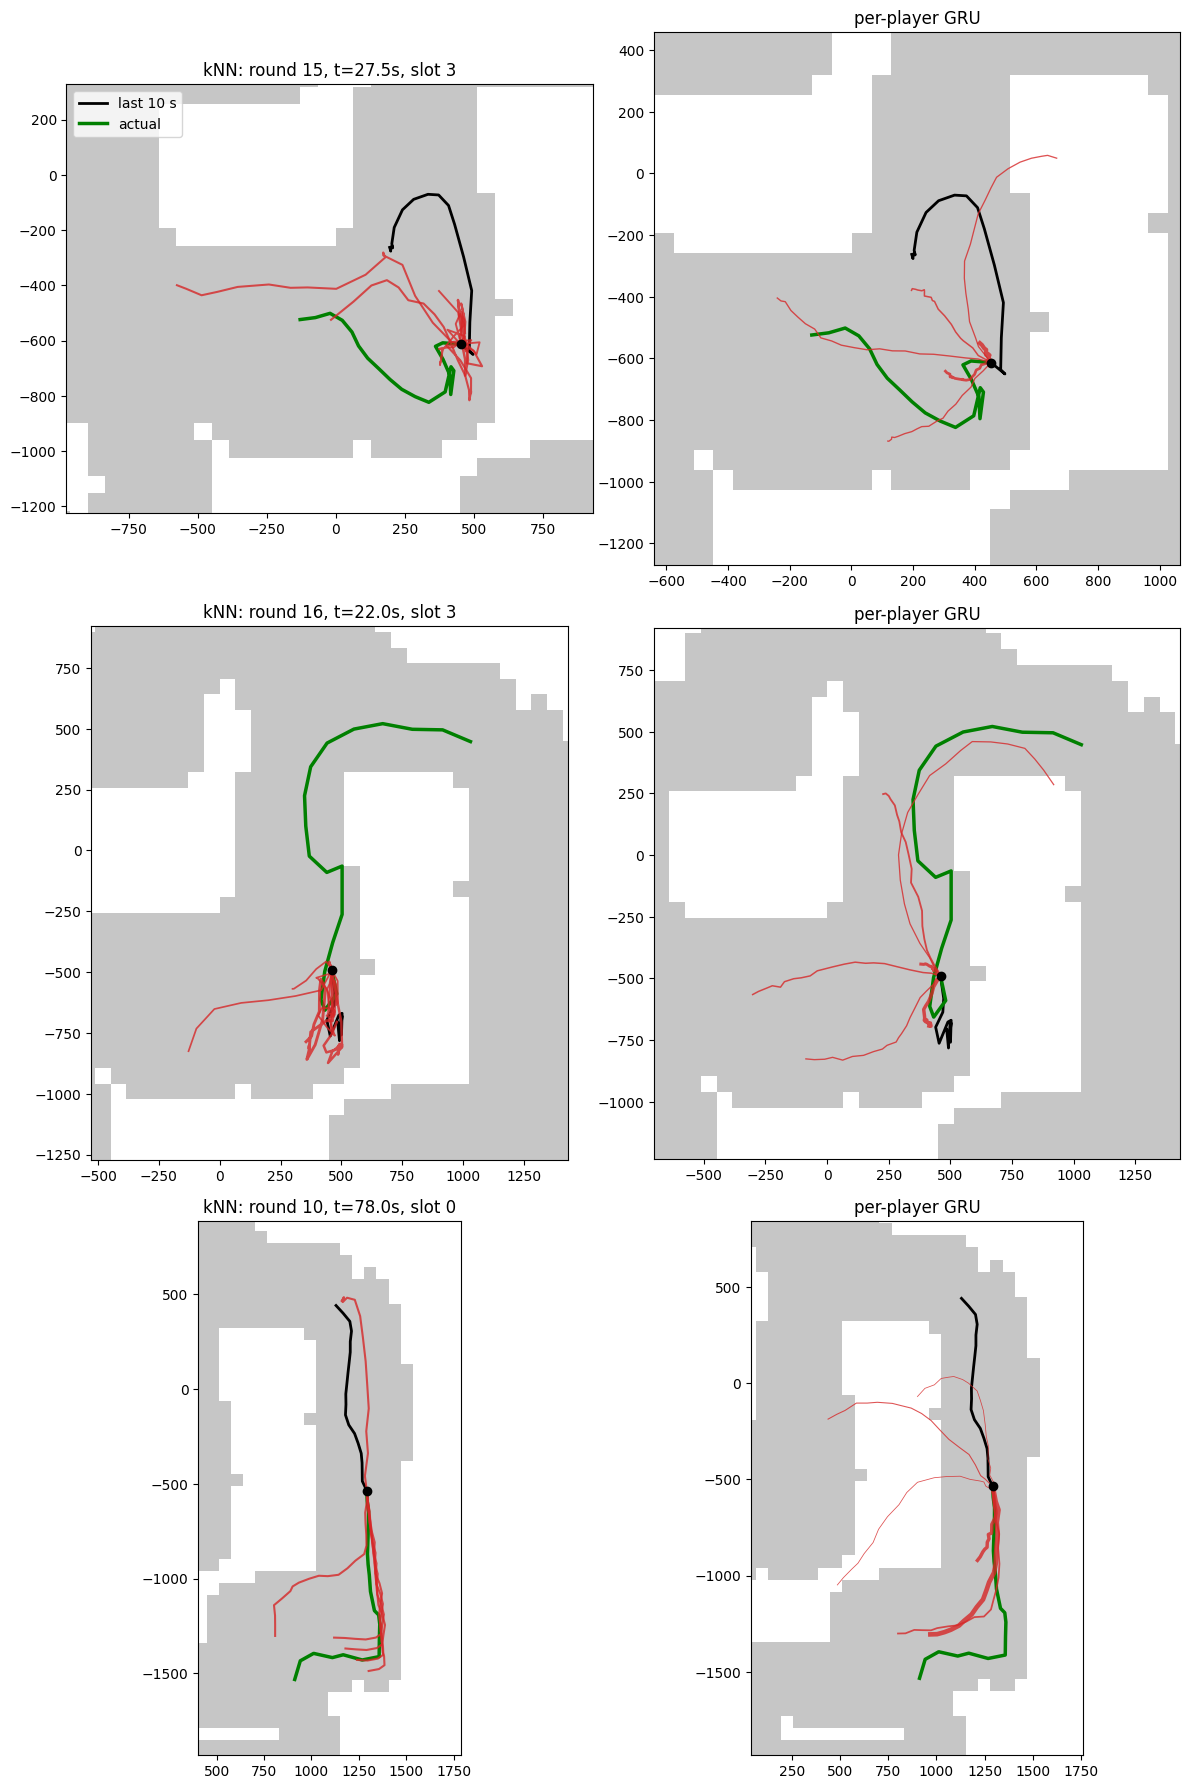

In [12]:
def draw(ax, i, pred, prob, title):
    extent = [grid_lo[0] * CELL, (grid_lo[0] + walkable.shape[0]) * CELL, grid_lo[1] * CELL, (grid_lo[1] + walkable.shape[1]) * CELL]
    ax.imshow(walkable.T, origin="lower", extent=extent, cmap="Greys", vmin=0, vmax=3)
    ax.plot(*test["hist"][i].T, "k-", lw=2, label="last 10 s")
    valid = test["mask"][i]
    ax.plot(*np.vstack([test["anchor"][i], test["fut"][i][valid]]).T, "g-", lw=2.5, label="actual")
    for k in range(pred.shape[1]):
        ax.plot(*np.vstack([test["anchor"][i], pred[i, k]]).T, "-", color="tab:red", lw=0.5 + 6 * prob[i, k], alpha=0.8)
    ax.plot(*test["anchor"][i], "ko")
    pts = np.vstack([test["hist"][i], test["fut"][i][valid], pred[i].reshape(-1, 2)])
    lo, hi = pts.min(0) - 400, pts.max(0) + 400
    ax.set_xlim(lo[0], hi[0])
    ax.set_ylim(lo[1], hi[1])
    ax.set_title(title)
    ax.set_aspect("equal")


candidates = np.flatnonzero(test["moving"] & test["mask"][:, -1])
fig, axes = plt.subplots(3, 2, figsize=(12, 18))
for row, i in zip(axes, rng.choice(candidates, len(axes), replace=False)):
    demo_idx, r, t, s = test["meta"][i]
    draw(row[0], i, *knn_pred, f"kNN: round {r + 1}, t={t * STEP_SECONDS:.1f}s, slot {s}")
    draw(row[1], i, *gru_pred, "per-player GRU")
axes[0, 0].legend(loc="upper left")
plt.tight_layout()

## Notes

- With only a handful of demos (one validation and one test match right now), these numbers are noisy.
  Re-run this notebook after adding demos with `build_dataset.py`.
- The kNN feature weights and GRU size are hand-picked, not tuned. Tuning them on the validation
  split would make the baselines stronger, which makes beating them more meaningful.
- The off-map metric uses training positions as the walkable area. A Mirage nav mesh (e.g. from
  awpy) would give an exact version.